# Rubik engine tour

`rubik` is a Rust 3x3x3 engine exposed to Python. It models bandaged cubes and searches for
short algorithms: edge/corner **3-cycles**, **2-edge flips**, **2-corner twists**.

Notation: `R U F L D B` (+ `2`, `'`), slices `M E S`, wide `r`/`Rw`, rotations `x y z`,
groups `(R U)3`, commutators `[R, U]`, conjugates `[F: R U R']`.

In [2]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import rubik

pd.set_option("display.width", 140)

## 1. The cube

In [3]:
c = rubik.Cube()
c.apply("R U R' U'")
print(c)                       # text net: U on top, then L F R B, then D
print(c.effect()["description"])

      U U L
      U U F
      U U F
B L L F F D R R U B R R
L L L F F U B R R B B B
L L L F F F U R R B B B
      D D R
      D D D
      D D D

(UR UB FR) (URF- DFR-) (ULB- UBR)


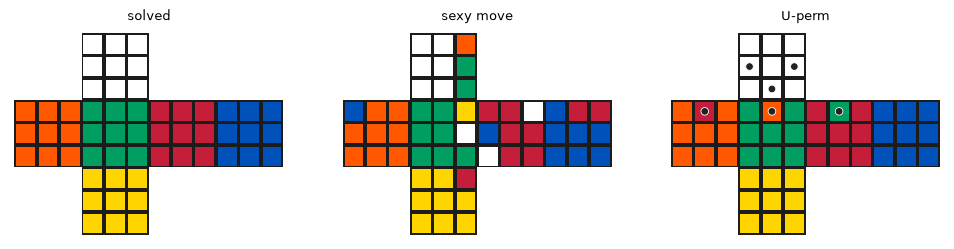

In [4]:
rubik.plot_cubes(
    [rubik.Cube(alg=a) for a in ["", "R U R' U'", "M2 U M U2 M' U M2"]],
    titles=["solved", "sexy move", "U-perm"],
    highlights=[None, None, rubik.analyze("M2 U M U2 M' U M2")["affected"]],
);

## 2. Bandaging

A bandage is a list of blocks; the cubies of a block always move together. A turn is legal only
if no block is cut by the turning layers. Blocks can be written as a string
(`"UF+UFR+UR+U | DF+D"`), a list of strings or a list of lists.

blocks     : [['URF', 'UR', 'UF', 'U'], ['DF', 'D']]
legal moves: ['L', 'L2', "L'", 'U', 'U2', "U'", 'D', 'D2', "D'", 'B', 'B2', "B'"]
can do R?  : False
blocked    : move 2 (F) is blocked by the bandage


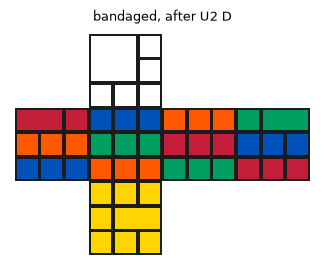

In [5]:
BAND = "UF+UFR+UR+U | DF+D"     # a 2x2x1 block on U and a center+edge block on D
b = rubik.Cube(bandage=BAND)
print("blocks     :", b.bandage)
print("legal moves:", b.legal_moves())
print("can do R?  :", b.can_apply("R"))
try:
    b.apply("U F")
except ValueError as e:
    print("blocked    :", e)
rubik.plot_cube(b.copy().apply("U2 D"), title="bandaged, after U2 D");

## 3. Searching on the regular cube

`Solver` enumerates every state within `depth` moves (deduplicated). Queries pair states that
agree outside the target pieces, so algorithms up to `2*depth` moves are found;
`extra_depth` streams more moves on one side without storing them.

In [6]:
t = time.time()
plain = rubik.Solver(depth=6, max_nodes=10_000_000)
print(plain, f"built in {time.time()-t:.1f}s")
print("states per depth:", plain.layer_sizes)

Solver(depth=6, states=8240087, moves=18, blocks=0) built in 1.6s
states per depth: [1, 18, 243, 3240, 43239, 574908, 7618438]


In [7]:
res = plain.find("edge3", pieces=["UF", "UR", "UB"], pure=True, max_results=8)
rubik.to_dataframe(res)

,alg,length,qtm,effect,pieces,pure,kind
0,R2 U F B' R2 F' B U R2,9,12,(UR UF UB),"[UR, UF, UB]",True,edge3
1,R2 U' F B' R2 F' B U' R2,9,12,(UR UB UF),"[UR, UF, UB]",True,edge3
2,R2 D B2 R' L U2 R L' D' R2,10,14,(UR UF UB),"[UR, UF, UB]",True,edge3
3,R2 D L U2 R L' B2 R' D' R2,10,14,(UR UB UF),"[UR, UF, UB]",True,edge3
4,R2 D L' B2 R' L U2 R D' R2,10,14,(UR UF UB),"[UR, UF, UB]",True,edge3
5,R2 D R B2 R' L U2 L' D' R2,10,14,(UR UF UB),"[UR, UF, UB]",True,edge3
6,R2 D R L' B2 R' L U2 D' R2,10,14,(UR UF UB),"[UR, UF, UB]",True,edge3
7,R2 D R' L U2 R L' B2 D' R2,10,14,(UR UB UF),"[UR, UF, UB]",True,edge3


In [8]:
t = time.time()
twists = plain.find("corner_twist", pieces=["URF", "UBR"], extra_depth=1, max_results=6)
print(f"{time.time()-t:.1f}s", plain.last_stats)
rubik.to_dataframe(twists)

4.8s {'candidates': 208, 'illegal': 0, 'matched': 104, 'truncated': False}


,alg,length,qtm,effect,pieces,pure,kind
0,B D' B2 U R2 U' R2 B U' B2 D B2 U,13,18,URF- UBR+,"[URF, UBR]",True,corner_twist
1,B R' U2 R U2 R B R' B2 L U2 L' U2,13,18,URF+ UBR-,"[URF, UBR]",True,corner_twist
2,B U2 B R' D2 R B' U2 B R' D2 R B2,13,18,URF- UBR+,"[URF, UBR]",True,corner_twist
3,B' L B2 R' U2 R U2 B' R B2 L' B2 R',13,18,URF+ UBR-,"[URF, UBR]",True,corner_twist
4,B' R2 B' U L2 U' B R2 B' U L2 U' B2,13,18,URF+ UBR-,"[URF, UBR]",True,corner_twist
5,B' U R2 U' R2 U' B' U B2 D' R2 D R2,13,18,URF- UBR+,"[URF, UBR]",True,corner_twist


In [9]:
flips = plain.find("edge_flip", pieces=["UF", "UR"], extra_depth=1, max_results=6)
rubik.to_dataframe(flips)

,alg,length,qtm,effect,pieces,pure,kind
0,B' R' F R B U2 F' U' F' U F2 U2 F',13,16,UR* UF*,"[UR, UF]",True,edge_flip
1,B' R2 F2 R F' R' F' R2 B U F U' F',13,16,UR* UF*,"[UR, UF]",True,edge_flip
2,F B U F' U' B' R2 F R F R' F2 R2,13,16,UR* UF*,"[UR, UF]",True,edge_flip
3,F B U2 F2 U' F U F U2 B' R' F' R,13,16,UR* UF*,"[UR, UF]",True,edge_flip
4,F R' F' L' U2 R U R U' R2 U2 R L,13,16,UR* UF*,"[UR, UF]",True,edge_flip
5,F R' F' R' F2 L D R D' R' L' F2 R2,13,16,UR* UF*,"[UR, UF]",True,edge_flip


## 4. Searching on a bandaged cube

The move set is restricted at every step, so the table can go much deeper. Every reported
algorithm is replayed on the bandaged cube: it is legal and restores the bandage shape.

In [10]:
t = time.time()
band = rubik.Solver(bandage=BAND, depth=40, max_nodes=4_000_000)
print(band, f"built in {time.time()-t:.1f}s, complete={band.reached_max_depth}")

Solver(depth=7, states=1444743, moves=18, blocks=2) built in 1.8s, complete=False


In [11]:
summary = []
for kind in ["edge3", "corner3", "edge_flip", "corner_twist", "orient"]:
    r = band.find(kind, unique_effects=True, max_results=10_000)
    lengths = [x["length"] for x in r]
    summary.append(dict(kind=kind, distinct_effects=len(r),
                        shortest=min(lengths, default=None), longest=max(lengths, default=None)))
pd.DataFrame(summary)

,kind,distinct_effects,shortest,longest
0,edge3,672,6,14
1,corner3,630,8,14
2,edge_flip,33,13,14
3,corner_twist,38,13,14
4,orient,195,13,14


In [12]:
cycles = band.find("edge3", pure=True, unique_effects=True, max_results=10)
rubik.to_dataframe(cycles)

,alg,length,qtm,effect,pieces,pure,kind
0,B2 U D' R2 U' D,6,8,(FR BR BL),"[FR, BL, BR]",True,edge3
1,B2 U' D L2 U D',6,8,(FL BL BR),"[FL, BL, BR]",True,edge3
2,D L2 U D' B2 U',6,8,(FL BR BL),"[FL, BL, BR]",True,edge3
3,L2 U' D F2 U D',6,8,(FR FL BL),"[FR, FL, BL]",True,edge3
4,U D' R2 U' D B2,6,8,(FR BL BR),"[FR, BL, BR]",True,edge3
5,U' D F2 U D' L2,6,8,(FR BL FL),"[FR, FL, BL]",True,edge3
6,L U D' B2 U' D L,7,8,(UL DL BR),"[UL, DL, BR]",True,edge3
7,L U' D F2 U D' L,7,8,(UL FR DL),"[UL, DL, FR]",True,edge3
8,L' U D' B2 U' D L',7,8,(UL BR DL),"[UL, DL, BR]",True,edge3
9,L' U' D F2 U D' L',7,8,(UL DL FR),"[UL, DL, FR]",True,edge3


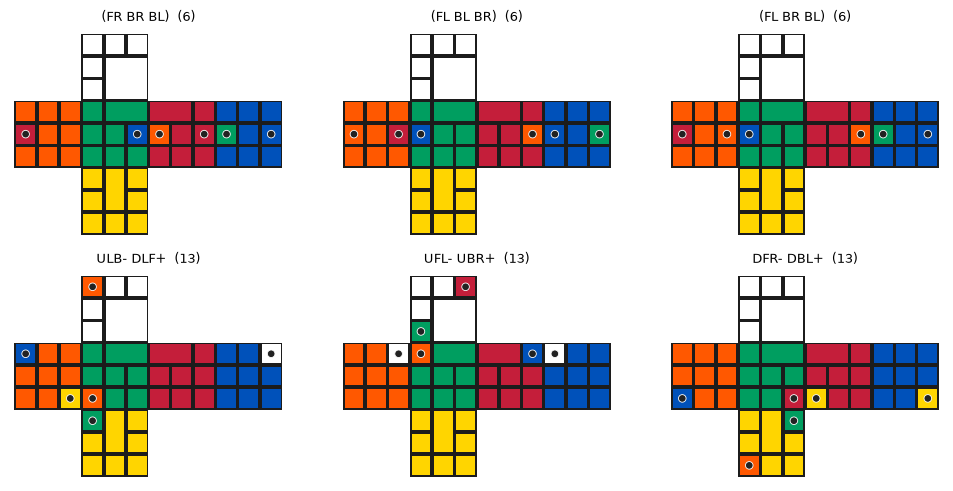

In [13]:
show = cycles[:3] + band.find("corner_twist", max_results=3)
rubik.plot_cubes(
    [rubik.Cube(bandage=BAND, alg=r["alg"]) for r in show],
    titles=[f'{r["effect"]}  ({r["length"]})' for r in show],
    highlights=[r["pieces"] for r in show],
);

### Which 3-cycles exist, and how short?

Pure edge 3-cycles reachable on the bandaged cube, shortest algorithm per triple.

84 edge triples can be cycled


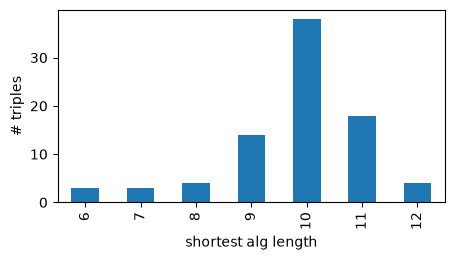

In [14]:
all_cycles = band.find("edge3", pure=True, unique_effects=True, max_results=100_000)
df = rubik.to_dataframe(all_cycles)
df["triple"] = df["pieces"].apply(lambda p: " ".join(sorted(p)))
best = df.groupby("triple")["length"].min().sort_values()
print(len(best), "edge triples can be cycled")
best.value_counts().sort_index().plot.bar(xlabel="shortest alg length", ylabel="# triples", figsize=(5, 2.5));

## 5. Tips

* `moves=` picks the move set: `"htm"` (default), `"stm"` (faces + slices), `"U M"`, `"R U F"`...
* Memory is ~40 bytes per stored state; `max_nodes` caps the table (it stops at a complete layer).
* `extra_depth` costs about *branching^extra_depth* × (states in the last layer); use `time_limit`.
* `kind="any"` with `pieces=[...]` finds anything confined to those pieces.
* `solver.distance(cube)` / `solver.path_to(cube)` give optimal distances for states in the table.